In [15]:
import string
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk import pos_tag, FreqDist
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords, wordnet, gutenberg, brown, movie_reviews
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer, WordNetLemmatizer

nltk.download(["punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng",
               "gutenberg", "brown", "movie_reviews"], quiet=True)

True

# Task 1. Nezeri arashdirma

**1. NLTK nedir?**

NLTK (Natural Language Toolkit) tebii dil, yeni insan dili ile islemek ucun Python kitabxanasidir. Icinde hazir korpuslar ve WordNet kimi lugetler var. Tokenizasiya, stop words, stemming, lemmatizasiya, POS tagging ve soz tezliyi analizi kimi NLP tapshiriqlarinda istifade olunur. Daha chox oyrenmek ve numune etmek ucun uygundur

**2. Tokenizasiya nedir?**

Tokenizasiya metni kichik hisselere (token) bolmekdir.
- **Sentence tokenization** (`sent_tokenize`) metni cumlelere bolur
- **Word tokenization** (`word_tokenize`) cumleni sozlere ve durgu isarelerine bolur

In [16]:
# Task 1
demo = "Dr. Smith didn't go to Baku. He stayed at home."
print(sent_tokenize(demo))
print(word_tokenize(demo))

["Dr. Smith didn't go to Baku.", 'He stayed at home.']
['Dr.', 'Smith', 'did', "n't", 'go', 'to', 'Baku', '.', 'He', 'stayed', 'at', 'home', '.']


**3. Stop words nedir?**

Stop words dilde chox tez-tez rast gelen, ozu az mena dashiyan sozlerdir (`the`, `is`, `and`).
- **Faydasi:** metn kichilir, hesablama suretlenir, esas sozler qalir
- **Zereri:** bezi stop words menani deyishir. Mes: `not` silinse `This movie is not good` cumlesi `movie good` olur

In [17]:
stop_words = set(stopwords.words("english"))
tokens = word_tokenize("This movie is not good".lower())
print(len(stop_words))
print(tokens)
print([w for w in tokens if w not in stop_words])

198
['this', 'movie', 'is', 'not', 'good']
['movie', 'good']


**4. Stemming ve lemmatizasiya**

- **Stemming** sozun sonunu qaydalarla kesir, netice real soz olmaya biler (`studies` -> `studi`)
- **Lemmatizasiya** sozu lugetdeki esas formasina getirir (`studies` -> `study`), amma yavashdir. Default olaraq her sozu isim sayir, ona gore `pos` vermek lazimdir
- **Porter** klassik metoddur, **Snowball** onun yaxshilashdirilmish versiyasidir, **Lancaster** ise en aqressiv metoddur, sozu chox qisaldir

In [18]:
porter = PorterStemmer()
snowball = SnowballStemmer("english")
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

words = ["running", "studies", "better", "was", "organization"]
pd.DataFrame({
    "Word": words,
    "Porter": [porter.stem(w) for w in words],
    "Snowball": [snowball.stem(w) for w in words],
    "Lancaster": [lancaster.stem(w) for w in words],
    "Lemma": [lemmatizer.lemmatize(w) for w in words],
    "Lemma (verb)": [lemmatizer.lemmatize(w, pos="v") for w in words],
})

,Word,Porter,Snowball,Lancaster,Lemma,Lemma (verb)
0,running,run,run,run,running,run
1,studies,studi,studi,study,study,study
2,better,better,better,bet,better,better
3,was,wa,was,was,wa,be
4,organization,organ,organ,org,organization,organization


**5. POS tagging nedir?**

POS tagging cumledeki her sozun nitq hissesini (isim, fel, sifet ve s.) mueyyen etmekdir. Bir nece etiket:
- `NN` - isim
- `VBZ` - fel
- `JJ` - sifet
- `RB` - zerf
- `DT` - teyinedici
- `IN` - qoshma

In [19]:
pos_tag(word_tokenize("The quick brown fox jumps over the lazy dog quickly"))

[('The', 'DT'),
 ('quick', 'JJ'),
 ('brown', 'NN'),
 ('fox', 'NN'),
 ('jumps', 'VBZ'),
 ('over', 'IN'),
 ('the', 'DT'),
 ('lazy', 'JJ'),
 ('dog', 'NN'),
 ('quickly', 'RB')]

**6. Corpus nedir?**

Corpus NLP ucun toplanmish boyuk metn kolleksiyasidir. NLTK-de hazir korpuslar var:
- **Gutenberg** - edebi kitablar (Alice in Wonderland, Moby Dick ve s.)
- **Brown** - amerikan ingilis dilinde muxtelif janrlarda (news, fiction, humor ...) metnler
- **Movie Reviews** - film reyleri, `pos` ve `neg` kateqoriyalarina bolunub

In [20]:
rows = []
for name, corpus in {"gutenberg": gutenberg, "brown": brown, "movie_reviews": movie_reviews}.items():
    rows.append({"Corpus": name, "Files": len(corpus.fileids()),
                 "Words": len(corpus.words()), "Sentences": len(corpus.sents())})
pd.DataFrame(rows)

,Corpus,Files,Words,Sentences
0,gutenberg,18,2621613,98552
1,brown,500,1161192,57340
2,movie_reviews,2000,1583820,71532


**7. FreqDist**

`FreqDist` metndeki her sozun nece defe rast gelindiyini sayir. `most_common(n)` ile en chox rast gelen n soz alinir. Soz tezliyi analizi ile metnin esas movzusunu tapmaq olur

# Task 2. Praktik hisse

In [21]:
# Task 2
text = (
    "Natural language processing is a field of computer science that helps computers understand human language. "
    "Researchers are studying how machines can read a text, translate sentences and answer questions about the text. "
    "Many people use these tools every day, for example when they are searching the web or talking to voice assistants. "
    "Before a model can learn from the data, the text is usually split into sentences and words. "
    "Very common words such as \"the\" and \"is\" are often removed, because these words carry little meaning. "
    "The remaining words are reduced to their base forms, and the most frequent words show what the text is mostly about."
)
sentences = sent_tokenize(text)
words = word_tokenize(text)
print(len(sentences))
print(words)

6
['Natural', 'language', 'processing', 'is', 'a', 'field', 'of', 'computer', 'science', 'that', 'helps', 'computers', 'understand', 'human', 'language', '.', 'Researchers', 'are', 'studying', 'how', 'machines', 'can', 'read', 'a', 'text', ',', 'translate', 'sentences', 'and', 'answer', 'questions', 'about', 'the', 'text', '.', 'Many', 'people', 'use', 'these', 'tools', 'every', 'day', ',', 'for', 'example', 'when', 'they', 'are', 'searching', 'the', 'web', 'or', 'talking', 'to', 'voice', 'assistants', '.', 'Before', 'a', 'model', 'can', 'learn', 'from', 'the', 'data', ',', 'the', 'text', 'is', 'usually', 'split', 'into', 'sentences', 'and', 'words', '.', 'Very', 'common', 'words', 'such', 'as', '``', 'the', "''", 'and', '``', 'is', "''", 'are', 'often', 'removed', ',', 'because', 'these', 'words', 'carry', 'little', 'meaning', '.', 'The', 'remaining', 'words', 'are', 'reduced', 'to', 'their', 'base', 'forms', ',', 'and', 'the', 'most', 'frequent', 'words', 'show', 'what', 'the', 'text

In [22]:
lower_words = [w.lower() for w in words]
no_punct = [w for w in lower_words if w.isalpha()]
clean_words = [w for w in no_punct if w not in stop_words]
print(len(words), len(no_punct), len(clean_words))
print(clean_words)

122 107 59
['natural', 'language', 'processing', 'field', 'computer', 'science', 'helps', 'computers', 'understand', 'human', 'language', 'researchers', 'studying', 'machines', 'read', 'text', 'translate', 'sentences', 'answer', 'questions', 'text', 'many', 'people', 'use', 'tools', 'every', 'day', 'example', 'searching', 'web', 'talking', 'voice', 'assistants', 'model', 'learn', 'data', 'text', 'usually', 'split', 'sentences', 'words', 'common', 'words', 'often', 'removed', 'words', 'carry', 'little', 'meaning', 'remaining', 'words', 'reduced', 'base', 'forms', 'frequent', 'words', 'show', 'text', 'mostly']


In [23]:
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


tagged = pos_tag(clean_words)
stem_words = ["researchers", "studying", "translate", "searching", "talking", "assistants",
              "removed", "reduced", "frequent", "processing", "machines", "sentences"]
pos_dict = dict(tagged)
pd.DataFrame({
    "Word": stem_words,
    "Porter": [porter.stem(w) for w in stem_words],
    "Snowball": [snowball.stem(w) for w in stem_words],
    "Lancaster": [lancaster.stem(w) for w in stem_words],
    "Lemma": [lemmatizer.lemmatize(w) for w in stem_words],
    "Lemma (POS)": [lemmatizer.lemmatize(w, get_wordnet_pos(pos_dict[w])) for w in stem_words],
})

,Word,Porter,Snowball,Lancaster,Lemma,Lemma (POS)
0,researchers,research,research,research,researcher,researcher
1,studying,studi,studi,study,studying,study
2,translate,translat,translat,transl,translate,translate
3,searching,search,search,search,searching,search
4,talking,talk,talk,talk,talking,talk
5,assistants,assist,assist,assist,assistant,assistant
6,removed,remov,remov,remov,removed,remove
7,reduced,reduc,reduc,reduc,reduced,reduce
8,frequent,frequent,frequent,frequ,frequent,frequent
9,processing,process,process,process,processing,processing


In [24]:
tagged

[('natural', 'JJ'),
 ('language', 'NN'),
 ('processing', 'NN'),
 ('field', 'NN'),
 ('computer', 'NN'),
 ('science', 'NN'),
 ('helps', 'VBZ'),
 ('computers', 'NNS'),
 ('understand', 'VBP'),
 ('human', 'JJ'),
 ('language', 'NN'),
 ('researchers', 'NNS'),
 ('studying', 'VBG'),
 ('machines', 'NNS'),
 ('read', 'VBN'),
 ('text', 'JJ'),
 ('translate', 'JJ'),
 ('sentences', 'NNS'),
 ('answer', 'VBP'),
 ('questions', 'NNS'),
 ('text', 'RB'),
 ('many', 'JJ'),
 ('people', 'NNS'),
 ('use', 'VBP'),
 ('tools', 'JJ'),
 ('every', 'DT'),
 ('day', 'NN'),
 ('example', 'NN'),
 ('searching', 'VBG'),
 ('web', 'NN'),
 ('talking', 'VBG'),
 ('voice', 'NN'),
 ('assistants', 'NNS'),
 ('model', 'NN'),
 ('learn', 'VBP'),
 ('data', 'NNS'),
 ('text', 'NN'),
 ('usually', 'RB'),
 ('split', 'VBD'),
 ('sentences', 'NNS'),
 ('words', 'NNS'),
 ('common', 'JJ'),
 ('words', 'NNS'),
 ('often', 'RB'),
 ('removed', 'VBD'),
 ('words', 'NNS'),
 ('carry', 'VBP'),
 ('little', 'JJ'),
 ('meaning', 'NN'),
 ('remaining', 'VBG'),
 ('wo

In [25]:
pd.DataFrame(tagged, columns=["Word", "Tag"])["Tag"].value_counts()

Tag
NNS    15
NN     14
JJ      9
VBP     6
RB      5
VBG     4
VBN     2
VBD     2
VBZ     1
DT      1
Name: count, dtype: int64

[('words', 5), ('text', 4), ('language', 2), ('sentences', 2), ('natural', 1), ('processing', 1), ('field', 1), ('computer', 1), ('science', 1), ('helps', 1)]


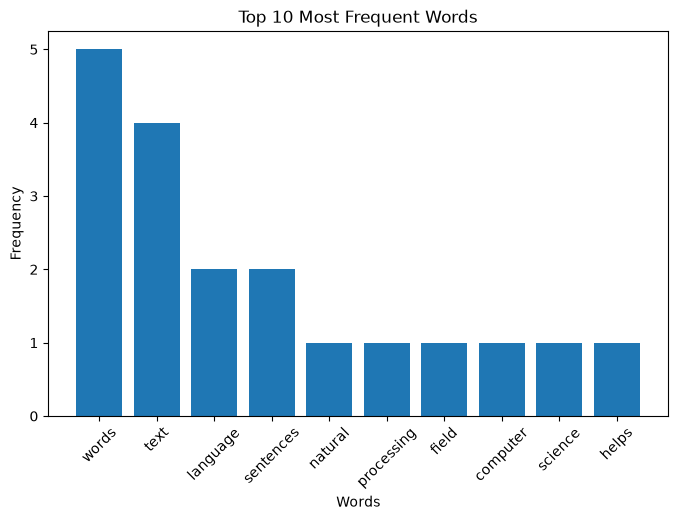

In [26]:
fd = FreqDist(clean_words)
top10 = fd.most_common(10)
print(top10)

plt.bar([w for w, c in top10], [c for w, c in top10])
plt.title("Top 10 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.gcf().set_size_inches(8, 5)
plt.show()

In [27]:
alice = gutenberg.raw("carroll-alice.txt")
alice_words = gutenberg.words("carroll-alice.txt")
print(alice[:300])
print()
print("Words:", len(alice_words))
print("Sentences:", len(gutenberg.sents("carroll-alice.txt")))
print("Unique words:", len(set(w.lower() for w in alice_words)))

[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversatio

Words: 34110
Sentences: 1703
Unique words: 2636


**Netice:** Gutenberg korpusundan Lewis Carroll-un Alice's Adventures in Wonderland. 34 110 soz, 1 703 cumle ve 2 636 unikal sozden ibaretdir

# Task 3. Yekun netice

NLTK metnle islemek ucun esas aletleri verir: tokenizasiya, stop words, stemming, lemmatizasiya, POS tagging ve FreqDist. En faydali olanlari tokenizasiya, stop words temizlenmesi ve FreqDist hesab edirem, chunki metnin esas movzusunu tez gorursen. Stemming suretlidir, amma `studi` kimi real olmayan sozler verir. Lemmatizasiya duzgundur, amma `pos` lazimdir. Porter ve Snowball eyni netice verdi, Lancaster ise daha aqressiv oldu. Chetinlik: `WordNetLemmatizer` default olaraq her sozu isim sayir, `not` stop words siyahisindadir ve silinende menani deyishir, kichik herfe chevirib stop words silenden sonra POS tagger sehv edir

Menbeler:
- https://www.nltk.org/
- https://www.nltk.org/book/
- https://en.wikipedia.org/wiki/Natural_language_processing